In [1]:
from anemone.forwards import *
import torch
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

In [2]:
from anemone.transforms import invFourier, coefficient_bounds

from anemone.experiment import lamontagne

def wv_to_t(t_eval, t_sampled, waveform=None):
    t_eval = t_eval.to(torch.double)
    t_sampled = t_sampled.to(torch.double)

    logT = torch.log(t_sampled)
    dT = logT[1]-logT[0]
    if waveform is None:
        t2t = lamontagne((torch.log(t_eval)[:,None]-logT[None,:])/dT)
    else:
        t2t = torch.zeros(t_eval.shape+t_sampled.shape, device=t_sampled.device, dtype=t_eval.dtype)

        for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
            t2t += k_wv*lamontagne((torch.log(t_eval-t_wv)[:,None]-logT[None,:])/dT)
    return t2t

class invFourier2(invFourier):
    def calc_tvals(self, tmin, tmax):
        rmin,rmax = self.f2r(tmin), self.f2r(tmax)
        if not isinstance(rmin, torch.Tensor): rmin = torch.tensor(rmin, device=self.device)
        if not isinstance(rmax, torch.Tensor): rmax = torch.tensor(rmax, device=self.device)
        imin = int(torch.floor(self.r_to_idx(rmin)))-2
        imax = int(torch.ceil( self.r_to_idx(rmax)))+2
        i_offsets = torch.arange(imin, imax, device=self.device)
        rout = self.idx_to_r(i_offsets).to(self.lamda.dtype)
        return i_offsets, rout, self.r2f(rout)

    def preintegrate(self, timeOperator, tmin, tmax, tolerance=None):
        i_offsets, rout, tout = self.calc_tvals(tmin, tmax)
        Wmat = timeOperator(tout).to(torch.complex128)

        if self.func_results is None:
            self.func_results = self.func(self.lamda)
            if not self.lambda_included: 
                self.func_results *= self.lamda


        if self.device is not None:
            rout = rout.to(self.device)
            Wmat = Wmat.to(self.device)
            i_offsets = i_offsets.to(self.device)
        if self.fc.dtype != self.func_results.dtype:
            self.fc = self.fc.to(self.func_results.dtype)   

        FC = torch.zeros(Wmat.shape[:-1]+self.fc.shape, dtype=torch.complex128, device=self.device)
        sqRout = torch.sqrt(rout)
        
        for i, i_offset in enumerate(i_offsets):
            if i_offset == 0:
                FC += Wmat[..., i, None]*self.fc*sqRout[i]/rout[i]
            elif i_offset > 0:
                FC[..., :-i_offset] += Wmat[..., i, None]*self.fc[i_offset:]*sqRout[i]/rout[i]
            else:
                i_offset *= -1
                FC[..., i_offset:] += Wmat[..., i, None]*self.fc[:-i_offset]*sqRout[i]/rout[i]
        
        
        if tolerance is not None:
            idxmin, idxmax = FC.shape[-1]-1, 0
            for i in range(len(FC)):
                cimin,cimax = coefficient_bounds(FC[i].cpu().numpy(), tolerance=tolerance)
                idxmin = min(idxmin, cimin)
                idxmax = max(idxmax, cimax)

            return torch.einsum('ij,...j->...i', FC, self.func_results), FC[..., idxmin:idxmax], self.lamda.squeeze()[idxmin:idxmax]
        else:
            return torch.einsum('ij,...j->...i', FC, self.func_results), FC, self.lamda.squeeze()

In [16]:
from anemone.forwards import *
import torch
import matplotlib.pyplot as plt
import numpy as np

class ForwardHankel7(Forward):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)
        self.t2t = None

    def forward(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb / c.fourpi
                intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                return torch.squeeze(intg)
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=1e-4)
            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega)
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier2(frq_integrand, smp_per_decade=16, device=self.device)
            def t2t_func(t_in):
                return wv_to_t(self.times, t_in, waveform=self.waveform)
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax, tolerance=1e-4)
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze())*self.omega1.squeeze())
        return Ht.real

In [17]:
from anemone.experiment import Loop, Receiver, Waveform
tx = Loop.square(40)
rx = Receiver()
wv = Waveform.example()
wv.time[-1] = 0.5e-6
wv.calc_d2wdt2()

t = torch.logspace(-6, -2, 51)

fwr1 = ForwardHankel7(tx, rx, t, waveform=wv)
fwr0 = Forward(tx, rx, t, waveform=wv)

rho = torch.tensor([1, 2, 0.5])*40.
thick = torch.ones(2)*30


n = 1
start = perf_counter()
dbdt1 = fwr1(rho, thick)
# dbdt1 = fwr1(rho, thick)
end = perf_counter()
print(f'Time for forward: {1e3*(end-start)/n:.2f} ms')

Time for forward: 183.68 ms


c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [18]:
n = 1000

rho = torch.tensor([1, 2, 0.5, 2, 0.5, 1.])*40.
rho = rho[:,None]*torch.ones(1, n)
rho[1] += torch.arange(n, device=rho.device).float()/10.

thick = torch.ones(len(rho)-1, n)*20

dbdts = fwr1(rho, thick)


start = perf_counter()
dbdt1 = fwr1(rho, thick)
end = perf_counter()
print(f'Time for forward: {1e3*(end-start)/n:.2f} ms')

Time for forward: 2.09 ms


In [19]:
%%timeit
dbdts = fwr1(rho, thick)

2.09 s ± 151 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [20]:
dbdts.shape

torch.Size([1000, 51])

In [21]:
rho = torch.tensor([1, 2, 0.5, 2, 0.5, 1.])*40.
# rho = rho[:,None]*torch.ones(1, 30)
# rho[1] += torch.arange(30, device=rho.device).float()/10.

thick = torch.ones(len(rho)-1)*20

dbdt1 = fwr1(rho, thick)
dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho*2, thick)
dbdt1 = fwr1(rho, thick)
dbdt2 = fwr1(rho, thick)

In [22]:
n = 1000
start = perf_counter()
for i in range(n):
    dbdt1 = fwr1(rho, thick)
end = perf_counter()
print(f'Time for forward: {1e3*(end-start)/n:.2f} ms')

Time for forward: 6.77 ms


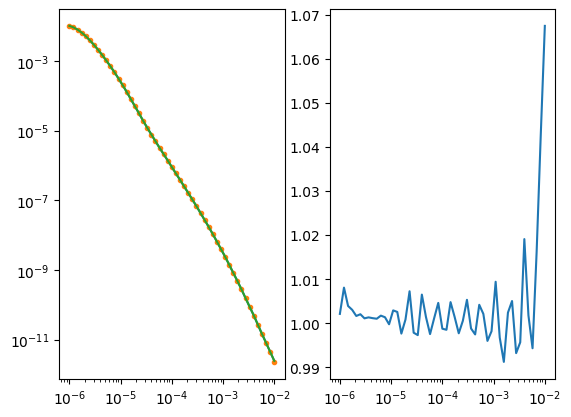

In [23]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(fwr1.times, dbdt1)
axs[0].loglog(fwr1.times,-dbdt1, 'C0--')
axs[0].loglog(fwr0.times, dbdt0, 'C1.')
axs[0].loglog(fwr0.times,-dbdt0, 'C1x')
axs[0].loglog(fwr1.times, dbdt2, 'C2')
axs[0].loglog(fwr1.times,-dbdt2, 'C2--')

axs[1].semilogx(fwr1.times, dbdt2/dbdt0)